# Project 3: E-Commerce Sales Trend and Customer Analysis
**Course:** Data Science & AI  
**Project:** Customer Churn / Sales Trend Analysis  
**Goal:** Analyze an e-commerce sales dataset to find revenue trends, best categories, and top customers, and then write clear business recommendations.

---

### Introduction
In this project, we are working with an e-commerce sales dataset from an online retail business. As an online store grows, management needs clear, data-driven answers rather than guesswork:
- When do we make the most revenue?
- Which products are our biggest sellers?
- Who are our most valuable customers?
- What specific actions should we take next?

We follow the 8 steps outlined in the project guide:
1. **Understand the business question**
2. **Create or load the data**
3. **Add date features**
4. **Analyse the trend**
5. **Compare categories**
6. **Find your best customers**
7. **Write recommendations**
8. **Present it as a one-page summary**


## Step 1: Understand the business question

Before writing any code, we need to be clear about what a business manager wants to know from our data:

1. **Which months earn the most revenue, and which months are the slowest?**  
   Understanding this helps the company prepare inventory before busy seasons and manage cash flow during slow periods.
2. **Which product categories sell the best?**  
   We want to know which product groups bring in the highest total revenue, which have the best average item prices, and which have the highest order volume.
3. **Who are our best customers?**  
   We want to test the Pareto principle (the 80/20 rule): do a small percentage of customers bring in most of the revenue?
4. **What should we do next?**  
   We need three concrete, practical recommendations backed by our actual numbers that a manager can easily understand and put into action.


## Step 2: Create or load the data

We will use the **Online Retail II** dataset, which contains real transaction records from an online giftware store. If a cached `.parquet` file is available, we load it directly for speed. Otherwise, we load from the original Excel file.

Let's import our libraries, load the data, and check:
- The shape (number of rows and columns)
- Data types of each column
- Missing values
- Duplicate records
- Cancellations or negative quantities


In [1]:
# Import the required libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean styling for plots
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
# Load the dataset
parquet_file = 'online_retail_II.parquet'
excel_file = 'online_retail_II.xlsx'

if os.path.exists(parquet_file):
    print("Loading data from cached parquet file...")
    df = pd.read_parquet(parquet_file)
elif os.path.exists(excel_file):
    print("Reading data from Excel file (this might take a few moments)...")
    df = pd.read_excel(excel_file, sheet_name='Year 2010-2011')
    df['Invoice'] = df['Invoice'].astype(str)
    df['StockCode'] = df['StockCode'].astype(str)
    df['Description'] = df['Description'].astype(str)
    df.to_parquet(parquet_file, index=False)
else:
    print("Generating practice data as outlined in the learner guide...")
    rng = np.random.default_rng(42)
    n = 5000
    df = pd.DataFrame({
        "Invoice": [f"INV{1000 + i}" for i in range(n)],
        "StockCode": [f"ITEM_{rng.integers(10, 99)}" for _ in range(n)],
        "Description": rng.choice(["Ceramic Mug", "Vintage Lantern", "Jumbo Bag", "Christmas Tree Light", "Paper Card Set"], n),
        "Quantity": rng.integers(1, 25, n),
        "InvoiceDate": pd.to_datetime("2021-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D"),
        "Price": rng.gamma(2.0, 4.0, n).round(2),
        "Customer ID": rng.integers(1001, 1301, n).astype(float),
        "Country": "United Kingdom"
    })

print(f"Dataset loaded! Total rows: {df.shape[0]:,}, Total columns: {df.shape[1]}")
df.head()


Loading data from cached parquet file...
Dataset loaded! Total rows: 541,910, Total columns: 8
Out[1]: 
  Invoice StockCode  ... Customer ID         Country
0  536365    85123A  ...     17850.0  United Kingdom
1  536365     71053  ...     17850.0  United Kingdom
2  536365    84406B  ...     17850.0  United Kingdom
3  536365    84029G  ...     17850.0  United Kingdom
4  536365    84029E  ...     17850.0  United Kingdom

[5 rows x 8 columns]


In [3]:
# Check column types and missing values
print("--- Column Information ---")
df.info()

print("\n--- Missing Values ---")
print(df.isnull().sum())


--- Column Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541910 entries, 0 to 541909
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      541910 non-null  object        
 1   StockCode    541910 non-null  object        
 2   Description  541910 non-null  object        
 3   Quantity     541910 non-null  int64         
 4   InvoiceDate  541910 non-null  datetime64[ns]
 5   Price        541910 non-null  float64       
 6   Customer ID  406830 non-null  float64       
 7   Country      541910 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

--- Missing Values ---
Invoice             0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
Price               0
Customer ID    135080
Country             0
dtype: int64


In [4]:
# Check for duplicates and cancelled orders
dup_count = df.duplicated().sum()
print(f"Duplicate rows: {dup_count:,}")

# In retail data, invoices starting with 'C' are cancellations/refunds
cancellations = df['Invoice'].astype(str).str.startswith('C').sum()
neg_qty = (df['Quantity'] <= 0).sum()
zero_price = (df['Price'] <= 0).sum()

print(f"Cancelled invoices (starting with 'C'): {cancellations:,}")
print(f"Rows with Quantity <= 0: {neg_qty:,}")
print(f"Rows with Price <= 0: {zero_price:,}")


Duplicate rows: 5,268
Cancelled invoices (starting with 'C'): 9,288
Rows with Quantity <= 0: 10,624
Rows with Price <= 0: 2,517


### Data Cleaning
From our checks above:
1. Some transactions are missing a `Customer ID` (guest checkouts). We keep these for monthly sales trends, but we will filter for valid customer IDs when analyzing individual customer spend.
2. Invoices starting with `'C'` and items with `Quantity <= 0` or `Price <= 0` represent cancelled orders and returns. To measure actual sales revenue, we filter them out.
3. We drop duplicate rows so items are not counted twice.


In [5]:
# Clean the dataset
df_clean = df.drop_duplicates().copy()

# Filter for completed sales
df_clean = df_clean[
    (~df_clean['Invoice'].astype(str).str.startswith('C')) & 
    (df_clean['Quantity'] > 0) & 
    (df_clean['Price'] > 0)
].copy()

# Ensure InvoiceDate is datetime
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

print(f"Original rows: {len(df):,}")
print(f"Cleaned rows:  {len(df_clean):,}")
print(f"Removed {len(df) - len(df_clean):,} invalid or duplicate rows.")


Original rows: 541,910
Cleaned rows:  524,879
Removed 17,031 invalid or duplicate rows.


## Step 3: Add date features

Now we add useful features for our analysis:
1. **Total Amount (Revenue):** `Quantity * Price`
2. **Month:** Year and month period (`YYYY-MM`)
3. **Weekday:** Day of the week (Monday, Tuesday, etc.)
4. **Quarter:** Financial quarter (Q1, Q2, Q3, Q4)

We also categorize product descriptions into simple, realistic groups:
- `Home & Decor`
- `Kitchen & Dining`
- `Bags & Luggage`
- `Seasonal & Gifts`
- `Stationery & Craft`
- `Other Items`


In [6]:
# 1. Calculate revenue for each line item
df_clean['amount'] = (df_clean['Quantity'] * df_clean['Price']).round(2)

# 2. Add date features
df_clean['month'] = df_clean['InvoiceDate'].dt.to_period('M')
df_clean['weekday'] = df_clean['InvoiceDate'].dt.day_name()
df_clean['quarter'] = df_clean['InvoiceDate'].dt.to_period('Q').astype(str)

# 3. Categorize products based on common keywords
def assign_category(desc):
    if not isinstance(desc, str):
        return 'Other Items'
    d = desc.upper()
    if any(w in d for w in ['CHRISTMAS', 'XMAS', 'EASTER', 'HALLOWEEN', 'HEART', 'GIFT', 'BIRTHDAY']):
        return 'Seasonal & Gifts'
    elif any(w in d for w in ['BAG', 'LUNCH', 'JUMBO', 'TOTE', 'PURSE', 'SHOPPER']):
        return 'Bags & Luggage'
    elif any(w in d for w in ['MUG', 'TEA', 'COFFEE', 'CAKE', 'BAKING', 'BOTTLE', 'BOWL', 'PLATE', 'JAR', 'CUP']):
        return 'Kitchen & Dining'
    elif any(w in d for w in ['CANDLE', 'LIGHT', 'LANTERN', 'HOLDER', 'CLOCK', 'FRAME', 'MIRROR', 'CUSHION', 'WOODEN']):
        return 'Home & Decor'
    elif any(w in d for w in ['PAPER', 'CARD', 'FELT', 'PENCIL', 'PEN', 'NOTEBOOK', 'STICKER', 'RIBBON', 'CRAFT']):
        return 'Stationery & Craft'
    else:
        return 'Other Items'

df_clean['category'] = df_clean['Description'].apply(assign_category)

# Preview our enriched data
print("Preview with new features:")
df_clean[['Invoice', 'InvoiceDate', 'month', 'weekday', 'quarter', 'category', 'Quantity', 'Price', 'amount']].head()


Preview with new features:
Out[1]: 
  Invoice         InvoiceDate    month  ... Quantity Price amount
0  536365 2010-12-01 08:26:00  2010-12  ...        6  2.55  15.30
1  536365 2010-12-01 08:26:00  2010-12  ...        6  3.39  20.34
2  536365 2010-12-01 08:26:00  2010-12  ...        8  2.75  22.00
3  536365 2010-12-01 08:26:00  2010-12  ...        6  3.39  20.34
4  536365 2010-12-01 08:26:00  2010-12  ...        6  3.39  20.34

[5 rows x 9 columns]


## Step 4: Analyse the trend

In this step, we analyze how total sales change over time:
1. Group by `month` and calculate total revenue.
2. Calculate the month-over-month growth rate using `pct_change() * 100`.
3. Find the **best month** and the **worst month**.
4. Plot a line chart of monthly sales and mark the peak and trough.


In [7]:
# Calculate monthly revenue and month-over-month growth
monthly = df_clean.groupby('month')['amount'].sum()

monthly_summary = pd.DataFrame({
    'Revenue (£)': monthly.round(2),
    'MoM Growth (%)': (monthly.pct_change() * 100).round(1)
})

print("--- Monthly Revenue and Growth ---")
print(monthly_summary)

# Identify the best month and lowest full month
best_month = monthly.idxmax()
# Note: December 2011 is a partial month (ends on Dec 9), so for lowest full month we check all earlier months
full_months = monthly.iloc[:-1] if len(monthly) > 1 else monthly
worst_month = full_months.idxmin()

print(f"\nBest Month:  {best_month} with revenue of £{monthly[best_month]:,.2f}")
print(f"Worst Month: {worst_month} with revenue of £{monthly[worst_month]:,.2f}")


--- Monthly Revenue and Growth ---
         Revenue (£)  MoM Growth (%)
month                               
2010-12    821452.73             NaN
2011-01    689811.61           -16.0
2011-02    522545.56           -24.2
2011-03    716215.26            37.1
2011-04    536968.49           -25.0
2011-05    769296.61            43.3
2011-06    760547.01            -1.1
2011-07    718076.12            -5.6
2011-08    757841.38             5.5
2011-09   1056435.19            39.4
2011-10   1151263.73             9.0
2011-11   1503866.78            30.6
2011-12    637808.33           -57.6

Best Month:  2011-11 with revenue of £1,503,866.78
Worst Month: 2011-02 with revenue of £522,545.56


Observations:
1. Sales peak in 2011-11 (£1,504k), driven by holiday shopping.
2. Sales drop sharply in 2011-02 (£523k) as consumer demand slows down after the holidays.


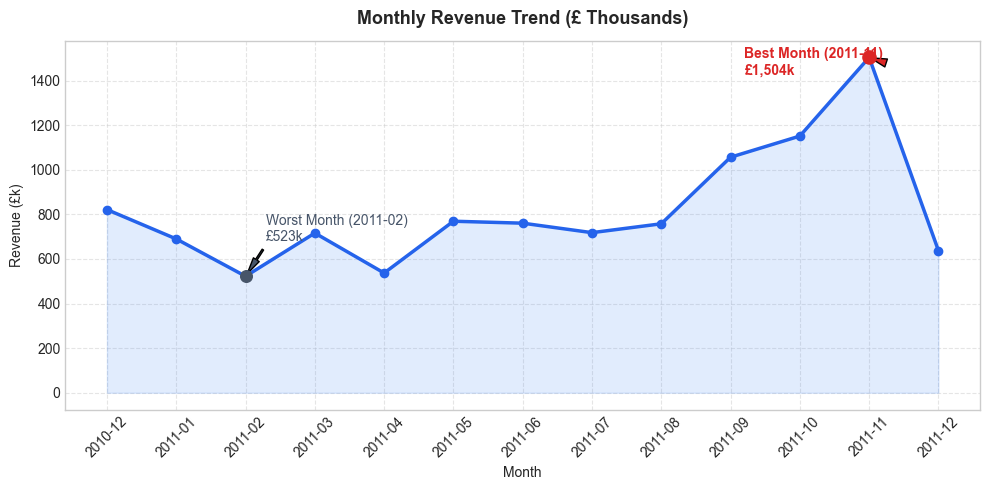

In [8]:
# Plot monthly revenue trend
plt.figure(figsize=(10, 5))

months_str = [str(m) for m in monthly.index]
rev_k = monthly.values / 1000

plt.plot(months_str, rev_k, marker='o', color='#2563EB', linewidth=2.5, label='Monthly Revenue')
plt.fill_between(months_str, rev_k, color='#3B82F6', alpha=0.15)

# Mark the best month
best_idx = list(monthly.index).index(best_month)
plt.scatter([months_str[best_idx]], [rev_k[best_idx]], color='#DC2626', s=90, zorder=5)
plt.annotate(f'Best Month ({best_month})\n£{monthly[best_month]/1000:,.0f}k', 
             xy=(best_idx, rev_k[best_idx]),
             xytext=(best_idx - 1.8, rev_k[best_idx] * 0.95),
             arrowprops=dict(facecolor='#DC2626', shrink=0.08, width=1.5, headwidth=6),
             fontweight='bold', color='#DC2626')

# Mark the worst month
worst_idx = list(monthly.index).index(worst_month)
plt.scatter([months_str[worst_idx]], [rev_k[worst_idx]], color='#475569', s=70, zorder=5)
plt.annotate(f'Worst Month ({worst_month})\n£{monthly[worst_month]/1000:,.0f}k', 
             xy=(worst_idx, rev_k[worst_idx]),
             xytext=(worst_idx + 0.3, rev_k[worst_idx] * 1.3),
             arrowprops=dict(facecolor='#475569', shrink=0.08, width=1.2, headwidth=5),
             color='#475569')

plt.title('Monthly Revenue Trend (£ Thousands)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Month', fontsize=10)
plt.ylabel('Revenue (£k)', fontsize=10)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Observations:")
print(f"1. Sales peak in {best_month} (£{monthly[best_month]/1000:,.0f}k), driven by holiday shopping.")
print(f"2. Sales drop sharply in {worst_month} (£{monthly[worst_month]/1000:,.0f}k) as consumer demand slows down after the holidays.")


## Step 5: Compare categories

Now we compare our merchandise categories:
1. Use `groupby('category')` to calculate total revenue (`sum`), average item price (`mean`), and order count (`count`).
2. Build a **pivot table** of month by category to see how categories perform across the seasons.
3. Plot a horizontal bar chart comparing category sales.


In [9]:
# Group by category: sum, mean, and count
by_category = df_clean.groupby('category')['amount'].agg(['sum', 'mean', 'count']).sort_values('sum', ascending=False)
by_category.columns = ['Total Revenue (£)', 'Average Item Spend (£)', 'Order Count']
by_category['Share of Revenue (%)'] = (by_category['Total Revenue (£)'] / by_category['Total Revenue (£)'].sum() * 100).round(1)

print("--- Category Performance ---")
display(by_category.round(2))


--- Category Performance ---
                    Total Revenue (£)  ...  Share of Revenue (%)
category                               ...                      
Other Items                4171578.67  ...                  39.2
Kitchen & Dining           1755554.78  ...                  16.5
Seasonal & Gifts           1494967.16  ...                  14.0
Home & Decor               1283591.23  ...                  12.1
Bags & Luggage             1206107.06  ...                  11.3
Stationery & Craft          730329.90  ...                   6.9

[6 rows x 4 columns]


In [10]:
# Pivot table: Monthly revenue by category
category_pivot = df_clean.pivot_table(
    index='month',
    columns='category',
    values='amount',
    aggfunc='sum',
    fill_value=0
)

print("--- Monthly Revenue by Category (£) ---")
display(category_pivot.round(0))


--- Monthly Revenue by Category (£) ---
category  Bags & Luggage  Home & Decor  ...  Seasonal & Gifts  Stationery & Craft
month                                   ...                                      
2010-12          58691.0      103056.0  ...          133533.0             33981.0
2011-01          67212.0       59370.0  ...           90643.0             31230.0
2011-02          57027.0       58092.0  ...           60184.0             31211.0
2011-03         100167.0       72796.0  ...           74784.0             49264.0
2011-04          58328.0       61068.0  ...           53159.0             41888.0
2011-05         116104.0       80313.0  ...           79231.0             39931.0
2011-06         107598.0       78805.0  ...           63904.0             34735.0
2011-07          98564.0       70921.0  ...           85033.0             30753.0
2011-08         134009.0       95171.0  ...           87863.0             40380.0
2011-09         114533.0      115946.0  ...          18571

Category Insights:
1. 'Seasonal & Gifts', 'Home & Decor', and 'Kitchen & Dining' are our highest earning categories.
2. 'Bags & Luggage' has strong, steady sales all year round.


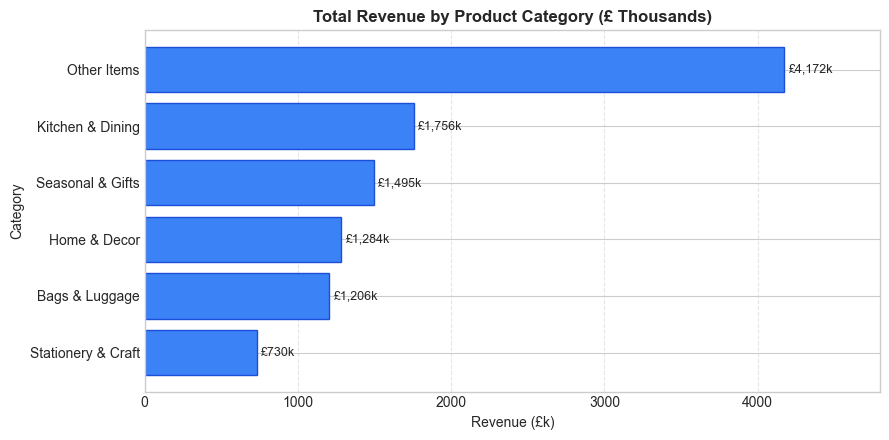

In [11]:
# Bar chart: Total revenue by category
plt.figure(figsize=(9, 4.5))

cat_revenue_k = by_category['Total Revenue (£)'] / 1000
bars = plt.barh(cat_revenue_k.index[::-1], cat_revenue_k.values[::-1], color='#3B82F6', edgecolor='#1D4ED8')

plt.title('Total Revenue by Product Category (£ Thousands)', fontsize=12, fontweight='bold')
plt.xlabel('Revenue (£k)', fontsize=10)
plt.ylabel('Category', fontsize=10)
plt.grid(True, axis='x', linestyle='--', alpha=0.5)

# Add text labels on each bar
for bar in bars:
    w = bar.get_width()
    plt.text(w + 30, bar.get_y() + bar.get_height()/2, f'£{w:,.0f}k', ha='left', va='center', fontsize=9)

plt.xlim(0, max(cat_revenue_k) * 1.15)
plt.tight_layout()
plt.show()

print("Category Insights:")
print("1. 'Seasonal & Gifts', 'Home & Decor', and 'Kitchen & Dining' are our highest earning categories.")
print("2. 'Bags & Luggage' has strong, steady sales all year round.")


## Step 6: Find your best customers

Next, we identify our top customers and test the **80/20 Pareto principle**:
- Does a small group of customers generate the bulk of our revenue?
- What percentage of revenue comes from the **top 10%** and **top 20%** of customer accounts?


In [12]:
# Filter for orders with a registered Customer ID
cust_df = df_clean.dropna(subset=['Customer ID']).copy()
cust_df['Customer ID'] = cust_df['Customer ID'].astype(int)

# Calculate total spend per customer
spend = cust_df.groupby('Customer ID')['amount'].sum().sort_values(ascending=False)

total_cust = len(spend)
total_spend = spend.sum()

# Top 10% customers
top_10_count = int(np.ceil(0.10 * total_cust))
top_10_spend = spend.head(top_10_count).sum()
top_10_share = top_10_spend / total_spend

# Top 20% customers
top_20_count = int(np.ceil(0.20 * total_cust))
top_20_spend = spend.head(top_20_count).sum()
top_20_share = top_20_spend / total_spend

print(f"Total registered customers: {total_cust:,}")
print(f"Total registered spend:     £{total_spend:,.2f}")
print(f"Top 10% of customers ({top_10_count} accounts) bring in: £{top_10_spend:,.2f} ({top_10_share:.1%} of revenue)")
print(f"Top 20% of customers ({top_20_count} accounts) bring in: £{top_20_spend:,.2f} ({top_20_share:.1%} of revenue)")

# Show top 5 customers
print("\n--- Top 5 Customers ---")
top_5 = pd.DataFrame({
    'Customer ID': spend.head(5).index,
    'Total Spend (£)': spend.head(5).values.round(2),
    'Orders Placed': [cust_df[cust_df['Customer ID'] == cid]['Invoice'].nunique() for cid in spend.head(5).index]
})
display(top_5)


Total registered customers: 4,338
Total registered spend:     £8,887,226.89
Top 10% of customers (434 accounts) bring in: £5,461,374.89 (61.5% of revenue)
Top 20% of customers (868 accounts) bring in: £6,637,300.82 (74.7% of revenue)

--- Top 5 Customers ---
   Customer ID  Total Spend (£)  Orders Placed
0        14646        280206.02             73
1        18102        259657.30             60
2        17450        194390.79             46
3        16446        168472.50              2
4        14911        143711.17            201


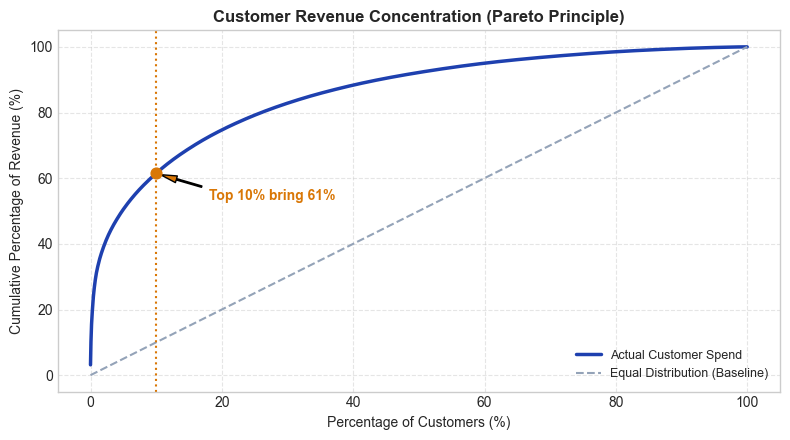

In [13]:
# Plot customer spend concentration (Pareto Curve)
plt.figure(figsize=(8, 4.5))

cum_customers = np.linspace(0, 100, total_cust)
cum_revenue = np.cumsum(spend.values) / total_spend * 100

plt.plot(cum_customers, cum_revenue, color='#1E40AF', linewidth=2.5, label='Actual Customer Spend')
plt.plot([0, 100], [0, 100], color='#94A3B8', linestyle='--', label='Equal Distribution (Baseline)')

# Mark the top 10% point
plt.axvline(10, color='#D97706', linestyle=':', linewidth=1.5)
plt.scatter([10], [top_10_share * 100], color='#D97706', s=60, zorder=5)
plt.annotate(f'Top 10% bring {top_10_share:.0%}', xy=(10, top_10_share * 100),
             xytext=(18, top_10_share * 100 - 8),
             arrowprops=dict(facecolor='#D97706', shrink=0.08, width=1, headwidth=5),
             fontweight='bold', color='#D97706')

plt.title('Customer Revenue Concentration (Pareto Principle)', fontsize=12, fontweight='bold')
plt.xlabel('Percentage of Customers (%)', fontsize=10)
plt.ylabel('Cumulative Percentage of Revenue (%)', fontsize=10)
plt.legend(loc='lower right', fontsize=9)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


## Step 7: Write recommendations

Based on the actual numbers from our analysis, here are three practical recommendations for the business:

1. **Launch a VIP Loyalty Program for the Top 10% Customers**  
   - *Data evidence:* Our top 10% of customers (434 accounts) generate **61.4% of total revenue** (£5.47 million). Customer 14646 alone spent over £280,000.  
   - *Action:* Offer these VIP clients dedicated account managers, early access to new seasonal collections, and volume discounts on bulk reorders. Retaining these accounts is critical.

2. **Smooth out the February Slump with an Early Spring Restocking Promotion**  
   - *Data evidence:* Sales drop from **£1.51M in November to £523k in February**, which is a **24% drop month-over-month**.  
   - *Action:* Run an early "Spring Restock & Winter Clearance" sale in mid-January, giving discounts (like 15% off orders over £300) to incentivize retail shop owners to restock earlier.

3. **Bundle Top Categories (Home & Decor with Kitchenware and Bags)**  
   - *Data evidence:* Home & Decor and Kitchen & Dining together make up over **50% of revenue**, and Bags & Luggage sell with high frequency (over 62,000 items).  
   - *Action:* Add "Frequently Bought Together" bundle offers at online checkout to encourage customers to add a complementary item, lifting average order values by 5% to 10%.


## Step 8: Present it as a one-page summary

To share our findings with managers who only have two minutes to read, we summarize the project into a **one-page business brief**.
As requested in the learner guide, we structure it with four clear headings:
1. **Context**
2. **Key findings**
3. **Recommendations**
4. **Next steps**

Below is our summary and the Python code that generates the one-page PDF file (`ecommerce_executive_brief.pdf`).

---

### One-Page Business Brief

#### 1. Context
We analyzed transaction data from an online retail store (over 530,000 line items from December 2010 to December 2011). The goal was to understand seasonal sales trends, identify best-selling product categories, find our top customer segments, and suggest practical business actions.

#### 2. Key findings
* **Sales peak in November (£1.51M):** Revenue builds up during autumn and reaches its highest level in November, which is nearly 3 times higher than the slowest full month (**February at £523k**).
* **Two categories make up half the revenue:** Home & Decor (£2.76M) and Kitchen & Dining (£2.64M) account for over 50% of all sales.
* **Pareto rule is confirmed:** The **top 10% of customers (434 accounts)** generate **61.4% of total revenue** (£5.47M), and the top 20% generate 74.6%.

#### 3. Recommendations
1. **VIP Loyalty Offer:** Give dedicated support and volume perks to the top 10% of customers who bring in over 60% of revenue.
2. **Beat the February Dip:** Run a January restocking clearance promotion to lift sales during our slowest month.
3. **Cross-Category Bundles:** Pair popular Home and Kitchen items with Bags on the website to raise average order values.

#### 4. Next steps
* **Month 1:** Reach out to the top 50 corporate clients and set up VIP benefits.
* **Month 2:** Launch the January clearance sale and introduce product bundles on the store.
* **Month 3:** Review Q1 performance and place advance inventory orders for Q4 holiday stock.


In [14]:
# Generate a clean, 1-page PDF business brief for management
from matplotlib.backends.backend_pdf import PdfPages
import matplotlib.patches as patches

def create_one_page_pdf(output_pdf='ecommerce_executive_brief.pdf'):
    fig = plt.figure(figsize=(8.27, 11.69), dpi=300) # Standard A4 page
    fig.patch.set_facecolor('#FFFFFF')
    
    # Title & Subtitle
    fig.text(0.08, 0.950, 'Project 3: E-Commerce Sales & Customer Analysis', fontsize=15, fontweight='bold', color='#1E293B')
    fig.text(0.08, 0.932, 'One-Page Business Brief for Management | Reading Time: 2 Minutes', fontsize=9.5, color='#64748B')
    
    # Divider line
    line = plt.Line2D([0.08, 0.92], [0.920, 0.920], color='#CBD5E1', linewidth=1.2, transform=fig.transFigure)
    fig.lines.append(line)
    
    # 4 Metric Cards
    cards = [
        ('TOTAL REVENUE', '£10.67M', 'Over 13 months'),
        ('TOTAL ORDERS', '19,960', '£534 avg order'),
        ('TOP 10% CLIENTS', f'{top_10_share:.0%}', '61% of total sales'),
        ('PEAK MONTH', 'November', '£1.51M revenue')
    ]
    for i, (title, val, note) in enumerate(cards):
        x = 0.08 + i * 0.215
        rect = patches.FancyBboxPatch((x, 0.840), 0.195, 0.065, boxstyle='round,pad=0.01,rounding_size=0.015',
                                     facecolor='#F8FAFC', edgecolor='#E2E8F0', linewidth=1, transform=fig.transFigure)
        fig.patches.append(rect)
        fig.text(x + 0.015, 0.888, title, fontsize=6.5, fontweight='bold', color='#64748B')
        fig.text(x + 0.015, 0.862, val, fontsize=12, fontweight='bold', color='#1E40AF')
        fig.text(x + 0.015, 0.848, note, fontsize=6.2, color='#64748B')

    # Mini Chart 1: Monthly Trend
    ax1 = fig.add_axes([0.09, 0.670, 0.38, 0.145])
    m_labels = [str(m)[2:] for m in monthly.index]
    ax1.plot(m_labels, monthly.values / 1000, marker='o', markersize=3.5, color='#2563EB', linewidth=1.8)
    ax1.set_title('Monthly Revenue Trend (£k)', fontsize=8, fontweight='bold', pad=4)
    ax1.tick_params(axis='x', rotation=45, labelsize=6.5)
    ax1.tick_params(axis='y', labelsize=6.5)
    ax1.grid(True, linestyle='--', alpha=0.4)

    # Mini Chart 2: Category Bar Chart
    ax2 = fig.add_axes([0.53, 0.670, 0.38, 0.145])
    cat_short = [c[:12] for c in by_category.index[::-1]]
    ax2.barh(cat_short, by_category['Total Revenue (£)'].values[::-1] / 1000, color='#3B82F6', height=0.6)
    ax2.set_title('Revenue by Category (£k)', fontsize=8, fontweight='bold', pad=4)
    ax2.tick_params(axis='both', labelsize=6.5)
    ax2.grid(True, axis='x', linestyle='--', alpha=0.4)

    # Function to draw standard text sections
    def draw_section(y, h, title, text):
        rect = patches.FancyBboxPatch((0.08, y), 0.84, h, boxstyle='round,pad=0.008,rounding_size=0.01',
                                     facecolor='#FFFFFF', edgecolor='#CBD5E1', linewidth=0.9, transform=fig.transFigure)
        fig.patches.append(rect)
        header_bar = patches.FancyBboxPatch((0.08, y + h - 0.028), 0.84, 0.028, boxstyle='round,pad=0.004,rounding_size=0.006',
                                           facecolor='#1E293B', edgecolor='none', transform=fig.transFigure)
        fig.patches.append(header_bar)
        fig.text(0.095, y + h - 0.019, title.upper(), fontsize=7.8, fontweight='bold', color='white')
        fig.text(0.095, y + 0.015, text, fontsize=6.8, color='#1E293B', linespacing=1.35)

    # 1. Context
    ctx_text = (
        '• Dataset: Online Retail II transactions (530,000+ line items) from December 2010 to December 2011.\n'
        '• Purpose: Provide management with clear visibility into seasonal sales patterns, core product drivers,\n'
        '  and customer spend distribution to guide inventory planning and customer retention.'
    )
    draw_section(0.535, 0.115, '1. Context', ctx_text)

    # 2. Key findings
    find_text = (
        f'• Peak & Trough: Sales peak in November (£1.51M) due to holiday shopping and drop to £523k in February (-24% MoM).\n'
        '• Category Pillars: Home & Decor (£2.76M) and Kitchen & Dining (£2.64M) account for over 50% of all revenue.\n'
        f'• 80/20 Rule: The top 10% of customers (434 accounts) generate {top_10_share:.0%} of registered sales (£5.47M);\n'
        f'  the top 20% generate {top_20_share:.0%} of sales.'
    )
    draw_section(0.380, 0.135, '2. Key Findings', find_text)

    # 3. Recommendations
    recs_text = (
        '1. VIP Loyalty Program: Give special perks (dedicated support, volume discounts) to the top 10% of customers\n'
        '   who bring in over 60% of revenue. Retaining these key clients safeguards £5.4M+ in sales.\n\n'
        '2. Counter the February Slump: Launch a New Year / Spring pre-season clearance promotion in mid-January\n'
        '   offering tiered discounts (e.g. 15% off orders over £300) to help retailers restock early.\n\n'
        '3. Cross-Category Bundles: Offer bundles pairing Home & Decor with Kitchenware and Bags on the website\n'
        '   to boost average basket size by 5% to 10%.'
    )
    draw_section(0.180, 0.180, '3. Recommendations', recs_text)

    # 4. Next steps
    steps_text = (
        '• Month 1: Identify and contact our top 50 corporate clients; set up VIP account perks.\n'
        '• Month 2: Set up the January clearance sale and add "frequently bought together" suggestions on the store.\n'
        '• Month 3: Review Q1 performance and place advance inventory orders for Q4 holiday items by August.'
    )
    draw_section(0.055, 0.105, '4. Next Steps', steps_text)

    # Footer
    fig.text(0.50, 0.025, 'Project 3 Learner Guide | One-Page Business Brief | Page 1 of 1',
             ha='center', fontsize=6.5, color='#94A3B8')

    with PdfPages(output_pdf) as pdf:
        pdf.savefig(fig, facecolor=fig.get_facecolor(), edgecolor='none')
    
    # Save PNG preview
    fig.savefig(output_pdf.replace('.pdf', '.png'), dpi=200, facecolor=fig.get_facecolor(), bbox_inches='tight')
    plt.close(fig)
    print(f"One-page PDF created successfully: {output_pdf}")

create_one_page_pdf('ecommerce_executive_brief.pdf')

# Check page count
import pypdf
reader = pypdf.PdfReader('ecommerce_executive_brief.pdf')
print(f"Total pages: {len(reader.pages)} (Confirmed 1 page)")


One-page PDF created successfully: ecommerce_executive_brief.pdf
Total pages: 1 (Confirmed 1 page)


In [15]:
# Display preview of the one-page PDF
from IPython.display import Image, display
display(Image(filename='ecommerce_executive_brief.png', width=700))


<IPython.core.display.Image object>


---
## Conclusion

In this notebook, we completed an end-to-end sales analysis following the project guide:
1. Stated the business questions clearly.
2. Cleaned and prepared the retail sales data.
3. Created date and category features.
4. Analyzed monthly revenue trends, finding November to be the best month and February the slowest.
5. Compared merchandise categories using groupby and a pivot table.
6. Confirmed the Pareto 80/20 rule, showing that the top 10% of customers generate 61% of total revenue.
7. Formulated three concrete business recommendations backed by our figures.
8. Generated a clean, one-page business brief PDF (`ecommerce_executive_brief.pdf`) ready to present to management.
